# 02 — Preprocess the CMU walking segments

Input: the `walking` folder made by notebook 01 (`segments/*.npz` + `walking_segments.csv`).

| Step | What happens |
|---|---|
| **0. Quality check** | **Frames:** missing frames (frame count vs. the source range), empty values (NaN/inf), sudden root jumps, sudden joint-rotation jumps, frozen (repeated) frames, unusual frame rate. **Joints:** all 52 SMPL+H joints present, no empty joint values. Short problems are repaired by interpolation; long ones mean the segment is dropped. Everything goes into `quality_report.csv`. |
| **1. Skeleton** | Runs the SMPL+H body model (forward kinematics) to get 3D positions of the 22 body joints. Then checks the skeleton: no empty joints, constant bone lengths, plausible body height. |
| **2. Floor** | Shifts each segment so the feet touch height 0. |
| **3. Resample** | 120 Hz (or 60 Hz) → 30 Hz. |
| **4. Windows** | Cuts fixed-length windows (default 60 frames = 2 s, 50 % overlap). |
| **5. Facing** | Each window starts at the origin, facing +x. |
| **6. Features** | Per frame: root height, root forward/sideways speed, turning speed, local joint positions, joint velocities, foot contacts. |
| **7. Ablation version** | Same features **without** the root speed (root-centred), for the root-velocity ablation. |
| **8. Split by person** | Train / val / test with no person in two sets. |
| **9. Normalise** | Mean and std from **train only**, applied to all splits. |
| **10. Check** | Rebuilds the skeleton from the features, measures the error, draws stick figures. |

Coordinates stay **z-up** (as in AMASS), in metres.

## Settings
Edit the paths here. You need the **SMPL+H body model** (`model.npz` files) from https://mano.is.tue.mpg.de → Downloads → *Extended SMPL+H model*. After unpacking you should have `male/model.npz`, `female/model.npz` (and maybe `neutral/model.npz`).

In [1]:
from pathlib import Path

WALK_DIR       = Path(r"C:\Users\hasna\Documents\Good Practise\CMU\walking")
SEG_DIR        = WALK_DIR / "segments"
SEG_CSV        = WALK_DIR / "walking_segments.csv"
BODY_MODEL_DIR = Path(r"C:\Users\hasna\Documents\Good Practise\smplh")   # folder with male/, female/ (neutral/)
OUT_DIR        = WALK_DIR / "preprocessed"

# Which segments to use (flags come from notebook 01)
KEEP_STYLIZED = True    # sad / drunk / zombie walks...
KEEP_TURNING  = True
KEEP_MIXED    = True

# Step 0: quality check
EXPECTED_FPS        = (60.0, 120.0)  # CMU in AMASS; other rates are flagged (and still resampled)
MAX_ROOT_SPEED      = 5.0     # m/s between two frames; faster = glitch
MAX_JOINT_SPEED_DEG = 1000.0  # deg/s rotation change of any body joint between frames; faster = glitch
MIN_FROZEN_RUN      = 3       # this many identical frames in a row = frozen frames
MAX_GAP_SEC         = 0.10    # longest run of bad frames that is repaired by interpolation
MAX_BAD_FRACTION    = 0.05    # more bad frames than this = drop the segment
HEAD_HEIGHT_RANGE   = (1.2, 2.0)  # m, head joint above the floor (skeleton check)
MAX_BONE_STD_MM     = 1.0     # bone lengths must stay constant

# Steps 3–6
TARGET_FPS     = 30
WINDOW_FRAMES  = 60           # 2 s at 30 Hz
STRIDE_FRAMES  = 30           # 50 % overlap
CONTACT_VEL    = 0.30         # m/s, foot slower than this ...
CONTACT_HEIGHT = {"L_ankle": 0.12, "R_ankle": 0.12, "L_foot": 0.07, "R_foot": 0.07}  # ... and lower than this = contact

# Step 8
SPLIT_RATIOS = (0.70, 0.15, 0.15)   # train, val, test (by number of windows)
SEED         = 42
SAME_PERSON  = []   # CMU sometimes gives one person several subject numbers, e.g. [[7, 8]] keeps 7 and 8 together

In [4]:
import json, warnings, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation, Slerp
from tqdm.auto import tqdm

assert SEG_DIR.exists(), f"Not found: {SEG_DIR} (run notebook 01 first)"

# ---- find the SMPL+H body model (male/model.npz, female/model.npz)
def find_body_model_dir():
    search_roots = [BODY_MODEL_DIR, BODY_MODEL_DIR.parent, Path.home() / "Downloads"]
    for root in search_roots:
        if not root.exists():
            continue
        # already unpacked?
        for p in root.rglob("model.npz"):
            if p.parent.name in ("male", "female", "neutral"):
                return p.parent.parent
        # downloaded but not unpacked yet? -> unpack into BODY_MODEL_DIR
        for arc in list(root.glob("*smplh*.tar.xz")) + list(root.glob("*smplh*.tar.bz2")) + list(root.glob("*smplh*.zip")):
            print("unpacking", arc)
            BODY_MODEL_DIR.mkdir(parents=True, exist_ok=True)
            if arc.suffix == ".zip":
                import zipfile; zipfile.ZipFile(arc).extractall(BODY_MODEL_DIR)
            else:
                with tarfile.open(arc) as t:
                    t.extractall(BODY_MODEL_DIR)
            for p in BODY_MODEL_DIR.rglob("model.npz"):
                if p.parent.name in ("male", "female", "neutral"):
                    return p.parent.parent
    return None

found = find_body_model_dir()
if found is None:
    raise FileNotFoundError(
        "SMPL+H body model not found.\n"
        "1. Register at https://mano.is.tue.mpg.de and sign in\n"
        "2. Downloads -> 'Extended SMPL+H model' (file smplh.tar.xz)\n"
        f"3. Put that file in {BODY_MODEL_DIR.parent} or your Downloads folder and re-run this cell\n"
        "   (it is unpacked automatically), or unpack it yourself so you have "
        f"{BODY_MODEL_DIR}\\male\\model.npz")
BODY_MODEL_DIR = found
print("body model folder:", BODY_MODEL_DIR, "->", sorted(p.parent.name for p in BODY_MODEL_DIR.glob("*/model.npz")))
OUT_DIR.mkdir(parents=True, exist_ok=True)

# SMPL body joints (first 22 of SMPL+H)
JOINT_NAMES = ["pelvis", "L_hip", "R_hip", "spine1", "L_knee", "R_knee", "spine2", "L_ankle", "R_ankle", "spine3",
               "L_foot", "R_foot", "neck", "L_collar", "R_collar", "head", "L_shoulder", "R_shoulder",
               "L_elbow", "R_elbow", "L_wrist", "R_wrist"]
J = {n: i for i, n in enumerate(JOINT_NAMES)}
N_BODY, N_ALL = 22, 52
FEET = [J["L_ankle"], J["R_ankle"], J["L_foot"], J["R_foot"]]
FOOT_NAMES = ["L_ankle", "R_ankle", "L_foot", "R_foot"]

segs = pd.read_csv(SEG_CSV)
keep = np.ones(len(segs), bool)
if not KEEP_STYLIZED: keep &= ~segs.stylized
if not KEEP_TURNING:  keep &= ~segs.turning
if not KEEP_MIXED:    keep &= segs.text_category != "mixed"
segs = segs[keep].reset_index(drop=True)
print(len(segs), "segments selected,", segs.subject.nunique(), "subjects")

unpacking C:\Users\hasna\Documents\Good Practise\smplh.tar.xz


C:\Users\hasna\AppData\Local\Temp\ipykernel_7764\3422120179.py:30: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(BODY_MODEL_DIR)


body model folder: C:\Users\hasna\Documents\Good Practise\smplh -> ['female', 'male', 'neutral']
477 segments selected, 50 subjects


## Step 0 — Frame and joint quality check
For every segment file:

- **Joints:** all 52 SMPL+H joints present (`poses` has 156 numbers per frame); which joints have empty values.
- **Frames:** frame count matches the source range from notebook 01 (otherwise frames are missing); `poses` and `trans` have the same number of frames; frame rate is expected.
- **Bad frames:** empty values, root jumps, joint-rotation jumps, frozen frames.

Bad frames at the very start or end are cut off. Bad frames inside are filled by interpolation (linear for position, spherical for rotations) if the gap is short. Otherwise the segment is dropped.

In [5]:
REQUIRED_KEYS = ["trans", "poses", "betas", "gender"]

def runs(mask):
    # (start, end) of each run of True values
    e = np.flatnonzero(np.diff(np.r_[0, mask.astype(int), 0]))
    return list(zip(e[::2], e[1::2]))

def quality_check(row):
    path = SEG_DIR / f"{row.segment_id}.npz"
    rec = dict(segment_id=row.segment_id, subject=row.subject, status="ok", issues="")
    issues = []
    def drop(msg):
        issues.append(msg); rec.update(status="dropped", issues="; ".join(issues)); return rec, None

    if not path.exists():
        return drop("file missing")
    d = dict(np.load(path, allow_pickle=True))
    missing = [k for k in REQUIRED_KEYS if k not in d]
    if missing:
        return drop(f"missing arrays: {missing}")
    fps = float(d.get("mocap_framerate", d.get("mocap_frame_rate", np.nan)))
    trans, poses, betas = d["trans"].astype(np.float64), d["poses"].astype(np.float64), d["betas"].astype(np.float64)
    T = len(trans)
    rec.update(fps=fps, n_frames=T, n_joints=poses.shape[1] // 3 if poses.ndim == 2 else 0)

    if len(poses) != T:
        return drop(f"missing frames: poses has {len(poses)} frames, trans has {T}")

    # --- joint checks
    if poses.ndim != 2 or poses.shape[1] != N_ALL * 3:
        return drop(f"joints: expected {N_ALL} joints ({N_ALL*3} values), found {poses.shape[-1]} values")
    nan_joints = np.flatnonzero(~np.isfinite(poses.reshape(T, N_ALL, 3)).all(axis=(0, 2)))
    rec["joints_with_empty_values"] = ",".join(str(j) for j in nan_joints)
    if not np.isfinite(betas).all():
        return drop("body shape (betas) has empty values")

    # --- frame checks
    expected = int(row.end_frame - row.start_frame)
    if T != expected:
        return drop(f"missing frames: {T} frames, expected {expected}")
    if not np.isfinite(fps) or fps <= 0:
        return drop("no frame rate")
    if not any(abs(fps - f) < 1e-3 for f in EXPECTED_FPS):
        issues.append(f"unusual frame rate {fps:g}")

    bad = ~np.isfinite(trans).all(1) | ~np.isfinite(poses).all(1)
    rec["empty_frames"] = int(bad.sum())

    tr = np.where(np.isfinite(trans), trans, 0.0)
    root_speed = np.linalg.norm(np.diff(tr, axis=0), axis=1) * fps
    jump = np.r_[False, root_speed > MAX_ROOT_SPEED] & ~bad & ~np.r_[False, bad[:-1]]
    rec["root_jump_frames"] = int(jump.sum())

    rv = np.where(np.isfinite(poses), poses, 0.0)[:, :N_BODY * 3].reshape(T, N_BODY, 3)
    r = Rotation.from_rotvec(rv.reshape(-1, 3))
    rmat = r.as_matrix().reshape(T, N_BODY, 3, 3)
    rel = np.einsum("tjba,tjbc->tjac", rmat[:-1], rmat[1:])           # R_{t-1}^T R_t
    ang = np.degrees(np.arccos(np.clip((np.trace(rel, axis1=2, axis2=3) - 1) / 2, -1, 1))) * fps
    pjump = np.r_[False, (ang > MAX_JOINT_SPEED_DEG).any(1)] & ~bad & ~np.r_[False, bad[:-1]]
    rec["joint_jump_frames"] = int(pjump.sum())

    same = np.r_[False, (poses[1:] == poses[:-1]).all(1) & (trans[1:] == trans[:-1]).all(1)]
    frozen = np.zeros(T, bool)
    for s, e in runs(same):
        if e - s + 1 >= MIN_FROZEN_RUN:
            frozen[s:e] = True
    rec["frozen_frames"] = int(frozen.sum())

    bad |= jump | pjump | frozen

    # cut bad frames at the start/end, repair inside
    good_idx = np.flatnonzero(~bad)
    if len(good_idx) < 2:
        return drop("no usable frames")
    a, b = good_idx[0], good_idx[-1] + 1
    rec.update(trim_start=int(a), trim_end=int(T - b))
    trans, poses, bad = trans[a:b], poses[a:b], bad[a:b]
    T2 = len(trans)
    n_bad = int(bad.sum())
    longest = max((e - s for s, e in runs(bad)), default=0)
    rec.update(bad_frames_inside=n_bad, longest_gap_frames=longest)
    if n_bad / T2 > MAX_BAD_FRACTION:
        return drop(f"{n_bad} bad frames ({100*n_bad/T2:.1f}%)")
    if longest > MAX_GAP_SEC * fps:
        return drop(f"gap of {longest} bad frames ({longest/fps:.2f} s)")

    if n_bad:
        t, g = np.arange(T2), ~bad
        for k in range(3):
            trans[bad, k] = np.interp(t[bad], t[g], trans[g, k])
        rv_all = poses.reshape(T2, N_ALL, 3)
        for j in range(N_ALL):
            rv_all[bad, j] = Slerp(t[g], Rotation.from_rotvec(rv_all[g, j]))(t[bad]).as_rotvec()
        poses = rv_all.reshape(T2, -1)
        issues.append(f"repaired {n_bad} frames")
        rec["status"] = "repaired"
    if a or T - b:
        issues.append(f"trimmed {a}+{T-b} edge frames")
        if rec["status"] == "ok": rec["status"] = "repaired"
    rec["issues"] = "; ".join(issues)
    gender = d["gender"]
    gender = gender.item() if hasattr(gender, "item") else gender
    gender = gender.decode() if isinstance(gender, bytes) else str(gender)
    return rec, dict(trans=trans, poses=poses, betas=betas, fps=fps, gender=gender)

qc_records, clean = [], {}
for row in tqdm(segs.itertuples(), total=len(segs), desc="quality check"):
    rec, data = quality_check(row)
    qc_records.append(rec)
    if data is not None:
        clean[row.segment_id] = data
qc = pd.DataFrame(qc_records)
qc.to_csv(OUT_DIR / "quality_report.csv", index=False)
print(qc.status.value_counts().to_string())
print("\nFrame rates:", qc.fps.value_counts().to_dict())
print("Problems found:")
for col in ["empty_frames", "root_jump_frames", "joint_jump_frames", "frozen_frames"]:
    if col in qc: print(f"  {col:18s}: {int(qc[col].fillna(0).gt(0).sum())} segments")
qc[qc.status != "ok"][["segment_id", "status", "issues"]]

quality check: 100%|██████████| 477/477 [00:11<00:00, 40.35it/s]

status
ok          306
repaired    170
dropped       1

Frame rates: {120.0: 450, 60.0: 27}
Problems found:
  empty_frames      : 0 segments
  root_jump_frames  : 0 segments
  joint_jump_frames : 171 segments
  frozen_frames     : 0 segments


,segment_id,status,issues
2,07_03_seg0,repaired,repaired 1 frames
4,07_05_seg0,repaired,repaired 1 frames
5,07_06_seg0,repaired,repaired 3 frames
7,07_08_seg0,repaired,repaired 1 frames
8,08_04_seg0,repaired,repaired 4 frames
...,...,...,...
468,91_33_seg1,repaired,repaired 2 frames
469,91_34_seg0,repaired,repaired 8 frames
470,91_35_seg0,repaired,repaired 1 frames
471,91_35_seg1,repaired,repaired 2 frames


## Step 1 — Skeleton: SMPL+H forward kinematics
Joint positions only depend on the body shape (`betas`) and the joint rotations, so the mesh is not needed. The result is 22 body joints × xyz per frame.

In [6]:
_models = {}
def load_body_model(gender):
    for g in [gender, "neutral", "male", "female"]:
        p = BODY_MODEL_DIR / g / "model.npz"
        if p.exists():
            if g != gender:
                warnings.warn(f"no {gender} model, using {g}")
            if g not in _models:
                m = np.load(p, allow_pickle=True)
                jr = m["J_regressor"]
                jr = jr.item().toarray() if jr.dtype == object else np.asarray(jr)
                parents = m["kintree_table"][0].astype(np.int64)
                parents[0] = -1
                _models[g] = dict(
                    J_template=jr @ m["v_template"],                                    # (52, 3)
                    J_shapedirs=np.einsum("jv,vck->jck", jr, m["shapedirs"]),           # (52, 3, K)
                    parents=parents)
            return _models[g]
    raise FileNotFoundError(f"No model.npz found in {BODY_MODEL_DIR}/<gender>/")

def body_joints(model, betas, poses, trans):
    K = model["J_shapedirs"].shape[-1]
    b = np.zeros(K); n = min(K, len(betas)); b[:n] = betas[:n]
    rest = model["J_template"] + model["J_shapedirs"] @ b                               # (52, 3)
    T, par = len(poses), model["parents"]
    R = Rotation.from_rotvec(poses[:, :N_BODY * 3].reshape(-1, 3)).as_matrix().reshape(T, N_BODY, 3, 3)
    G = np.empty((T, N_BODY, 3, 3)); pos = np.empty((T, N_BODY, 3))
    G[:, 0], pos[:, 0] = R[:, 0], rest[0]
    for j in range(1, N_BODY):
        p = par[j]
        G[:, j] = G[:, p] @ R[:, j]
        pos[:, j] = pos[:, p] + G[:, p] @ (rest[j] - rest[p])
    return pos + trans[:, None, :]

BONES = [(j, p) for j, p in enumerate(load_body_model("male")["parents"][:N_BODY]) if p >= 0]

joints_hr, skel_checks = {}, []
for sid, d in tqdm(clean.items(), desc="skeleton"):
    X = body_joints(load_body_model(d["gender"]), d["betas"], d["poses"], d["trans"])
    floor = np.percentile(X[:, FEET, 2].min(1), 5)
    bone_len = np.stack([np.linalg.norm(X[:, j] - X[:, p], axis=1) for j, p in BONES], 1)
    head = np.median(X[:, J["head"], 2] - floor)
    ok = np.isfinite(X).all() and bone_len.std(0).max() * 1000 <= MAX_BONE_STD_MM and HEAD_HEIGHT_RANGE[0] <= head <= HEAD_HEIGHT_RANGE[1]
    skel_checks.append(dict(segment_id=sid, empty_joint_values=int((~np.isfinite(X)).sum()),
                            max_bone_std_mm=bone_len.std(0).max() * 1000, head_height_m=head, skeleton_ok=ok))
    if ok:
        # Step 2 — floor at height 0
        X[..., 2] -= floor
        joints_hr[sid] = X

skel = pd.DataFrame(skel_checks)
qc = qc.merge(skel, on="segment_id", how="left")
qc.loc[qc.skeleton_ok.eq(False), "status"] = "dropped"
qc.loc[qc.skeleton_ok.eq(False), "issues"] = qc.issues.fillna("") + "; skeleton check failed"
qc.to_csv(OUT_DIR / "quality_report.csv", index=False)
print(f"{len(joints_hr)} segments passed the skeleton check, {int((~skel.skeleton_ok).sum())} failed")
skel.describe().loc[["min", "max"], ["max_bone_std_mm", "head_height_m"]]

skeleton: 100%|██████████| 476/476 [00:02<00:00, 209.74it/s]

470 segments passed the skeleton check, 6 failed


,max_bone_std_mm,head_height_m
min,6.317262e-13,1.057660
max,7.624864e-11,1.621019


## Steps 3–7 — Resample, cut windows, face +x, build features

In [7]:
def resample(x, fps, new_fps):
    t_old = np.arange(len(x)) / fps
    t_new = np.arange(0, t_old[-1] + 1e-9, 1 / new_fps)
    return interp1d(t_old, x, axis=0)(t_new)

def heading(Jt):
    # yaw angle of the facing direction (forward = (left-right) x up), smoothed
    across = (Jt[:, J["L_hip"]] - Jt[:, J["R_hip"]]) + (Jt[:, J["L_shoulder"]] - Jt[:, J["R_shoulder"]])
    th = np.unwrap(np.arctan2(-across[:, 0], across[:, 1]))     # = atan2(fwd_y, fwd_x) with fwd = (a_y, -a_x)
    return savgol_filter(th, 7, 2) if len(th) >= 7 else th

def rot_xy(v, ang):
    # rotate the xy part of v (T, ..., 3) by angle ang (T,) about z
    c, s = np.cos(ang), np.sin(ang)
    shape = (len(ang),) + (1,) * (v.ndim - 2)
    c, s = c.reshape(shape), s.reshape(shape)
    out = v.copy()
    out[..., 0] = c * v[..., 0] - s * v[..., 1]
    out[..., 1] = s * v[..., 0] + c * v[..., 1]
    return out

def fdiff(a, fps):
    d = np.empty_like(a); d[:-1] = a[1:] - a[:-1]; d[-1] = d[-2]
    return d * fps

def canonical_window(Jw):
    th = heading(Jw)
    Jc = Jw.copy()
    Jc[..., :2] -= Jw[0, 0, :2]
    return rot_xy(Jc, np.full(len(Jc), -th[0]))

def make_features(Jc, fps=TARGET_FPS):
    th = heading(Jc)                                  # th[0] == 0 after canonical_window
    root = Jc[:, 0]
    root_vel = rot_xy(np.c_[fdiff(root[:, :2], fps), np.zeros(len(root))], -th)[:, :2]   # forward, sideways
    yaw_rate = fdiff(th, fps)
    rel = Jc[:, 1:].copy(); rel[..., :2] -= root[:, None, :2]                          # xy relative, z = height
    local = rot_xy(rel, -th)
    vel = rot_xy(fdiff(Jc[:, 1:], fps), -th)
    rel_vel = fdiff(local, fps)
    fspeed = np.linalg.norm(fdiff(Jc[:, FEET], fps), axis=-1)
    contact = np.stack([(fspeed[:, i] < CONTACT_VEL) & (Jc[:, FEET[i], 2] < CONTACT_HEIGHT[n])
                        for i, n in enumerate(FOOT_NAMES)], 1).astype(float)
    T = len(Jc)
    full = np.concatenate([root[:, 2:3], root_vel, yaw_rate[:, None],
                           local.reshape(T, -1), vel.reshape(T, -1), contact], 1)
    noroot = np.concatenate([root[:, 2:3], local.reshape(T, -1), rel_vel.reshape(T, -1), contact], 1)
    return full.astype(np.float32), noroot.astype(np.float32)

xyz = lambda pre: [f"{pre}{n}_{a}" for n in JOINT_NAMES[1:] for a in "xyz"]
FEATURES = (["root_height", "root_vel_forward", "root_vel_sideways", "root_yaw_rate"]
            + xyz("pos_") + xyz("vel_") + [f"contact_{n}" for n in FOOT_NAMES])
FEATURES_NOROOT = ["root_height"] + xyz("pos_") + xyz("relvel_") + [f"contact_{n}" for n in FOOT_NAMES]
CONTACT_COLS = [i for i, f in enumerate(FEATURES) if f.startswith("contact_")]
CONTACT_COLS_NR = [i for i, f in enumerate(FEATURES_NOROOT) if f.startswith("contact_")]
print(len(FEATURES), "features per frame;", len(FEATURES_NOROOT), "in the no-root version")

def recover_joints(x, fps=TARGET_FPS):
    # Feature vector (T, D) -> joint positions (T, 22, 3). Use this later on decoded motion.
    T = len(x)
    th = np.r_[0.0, np.cumsum(x[:-1, 3]) / fps]
    v = rot_xy(np.c_[x[:, 1:3], np.zeros(T)], th)[:, :2]
    root_xy = np.r_[np.zeros((1, 2)), np.cumsum(v[:-1], 0) / fps]
    local = rot_xy(x[:, 4:4 + 63].reshape(T, 21, 3).astype(np.float64), th)
    local[..., :2] += root_xy[:, None]
    root = np.c_[root_xy, x[:, 0]][:, None]
    return np.concatenate([root, local], 1)

134 features per frame; 131 in the no-root version


In [8]:
seg_info = segs.set_index("segment_id")
X_full, X_nr, JW, meta = [], [], [], []
too_short = 0
for sid, Xhr in tqdm(joints_hr.items(), desc="windows"):
    Xs = resample(Xhr, clean[sid]["fps"], TARGET_FPS)
    if len(Xs) < WINDOW_FRAMES:
        too_short += 1
        continue
    info = seg_info.loc[sid]
    for k, s in enumerate(range(0, len(Xs) - WINDOW_FRAMES + 1, STRIDE_FRAMES)):
        Jc = canonical_window(Xs[s:s + WINDOW_FRAMES])
        f, fn = make_features(Jc)
        X_full.append(f); X_nr.append(fn); JW.append(Jc.astype(np.float32))
        meta.append(dict(window_id=f"{sid}_w{k}", segment_id=sid, subject=int(info.subject),
                         start_frame_30hz=s, description=info.description, text_category=info.text_category,
                         speed_label=info.speed_label, stylized=bool(info.stylized), turning=bool(info.turning),
                         fwd_speed_mps=float(f[:, 1].mean()),
                         net_speed_mps=float(np.linalg.norm(Jc[-1, 0, :2] - Jc[0, 0, :2]) / ((WINDOW_FRAMES - 1) / TARGET_FPS)),
                         sideways_speed_mps=float(f[:, 2].mean()),
                         turn_rate_deg_s=float(np.degrees(f[:, 3].mean())),
                         segment_cadence_spm=float(info.cadence_spm)))
X_full, X_nr, JW, meta = np.stack(X_full), np.stack(X_nr), np.stack(JW), pd.DataFrame(meta)
print(f"{len(meta)} windows of {WINDOW_FRAMES} frames from {meta.segment_id.nunique()} segments "
      f"({too_short} segments shorter than one window)")
print("feature arrays:", X_full.shape, X_nr.shape, " joints:", JW.shape)

windows: 100%|██████████| 470/470 [00:02<00:00, 189.98it/s]


2735 windows of 60 frames from 470 segments (0 segments shorter than one window)
feature arrays: (2735, 60, 134) (2735, 60, 131)  joints: (2735, 60, 22, 3)


## Step 8 — Split by person

In [9]:
person = {s: s for s in meta.subject.unique()}
for group in SAME_PERSON:
    for s in group:
        person[s] = min(group)
meta["person"] = meta.subject.map(person)

rng = np.random.default_rng(SEED)
persons = meta.person.unique()
rng.shuffle(persons)
counts = meta.person.value_counts()
total = counts.sum()
split_of, filled = {}, {"test": 0, "val": 0}
for p in persons:
    if len(persons) >= 3 and filled["test"] == 0:
        target = "test"
    elif len(persons) >= 3 and filled["val"] == 0:
        target = "val"
    elif filled["test"] < SPLIT_RATIOS[2] * total:
        target = "test"
    elif filled["val"] < SPLIT_RATIOS[1] * total:
        target = "val"
    else:
        target = "train"
    split_of[p] = target
    if target in filled:
        filled[target] += counts[p]
meta["split"] = meta.person.map(split_of)

summary = meta.groupby("split").agg(windows=("window_id", "size"), persons=("person", "nunique"),
                                    mean_speed=("fwd_speed_mps", "mean"), min_speed=("fwd_speed_mps", "min"),
                                    max_speed=("fwd_speed_mps", "max")).round(2)
print(summary)
for a in ["train", "val", "test"]:
    for b in ["train", "val", "test"]:
        if a < b:
            assert not set(meta.person[meta.split == a]) & set(meta.person[meta.split == b]), "person in two splits!"
print("\nNo person appears in two splits.")

       windows  persons  mean_speed  min_speed  max_speed
split                                                    
test       646       13        0.69      -0.02       1.49
train     1603       23        0.69      -0.00       1.59
val        486       14        0.74       0.05       1.60

No person appears in two splits.


## Step 9 — Normalise (statistics from train only)
Foot-contact columns (0/1) are left as they are.

In [10]:
def norm_stats(X, contact_cols):
    flat = X.reshape(-1, X.shape[-1]).astype(np.float64)
    mean, std = flat.mean(0), flat.std(0)
    std[std < 1e-6] = 1.0
    mean[contact_cols], std[contact_cols] = 0.0, 1.0
    return mean.astype(np.float32), std.astype(np.float32)

train = (meta.split == "train").values
mean, std = norm_stats(X_full[train], CONTACT_COLS)
mean_nr, std_nr = norm_stats(X_nr[train], CONTACT_COLS_NR)

for split in ["train", "val", "test"]:
    m = (meta.split == split).values
    np.savez_compressed(OUT_DIR / f"{split}.npz",
                        X=(X_full[m] - mean) / std,          # normalised features (N, T, D)
                        X_noroot=(X_nr[m] - mean_nr) / std_nr,
                        joints=JW[m],                        # canonical joint positions (N, T, 22, 3), metres
                        window_id=meta.window_id[m].values)
    meta[m].to_csv(OUT_DIR / f"{split}_meta.csv", index=False)

np.savez(OUT_DIR / "normalization.npz", mean=mean, std=std, mean_noroot=mean_nr, std_noroot=std_nr)
config = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, tuple, list, dict, bool))}
config.update(FEATURES=FEATURES, FEATURES_NOROOT=FEATURES_NOROOT, JOINT_NAMES=JOINT_NAMES,
              BONES=[[int(a), int(b)] for a, b in BONES], coordinate_system="z-up, metres, window starts at origin facing +x")
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2, default=str))
print("saved to", OUT_DIR)
print(sorted(p.name for p in OUT_DIR.iterdir()))

saved to C:\Users\hasna\Documents\Good Practise\CMU\walking\preprocessed
['config.json', 'normalization.npz', 'quality_report.csv', 'test.npz', 'test_meta.csv', 'train.npz', 'train_meta.csv', 'val.npz', 'val_meta.csv']


## Step 10 — Checks
**Round trip:** rebuild joint positions from the features and compare with the originals. The error should be close to zero. This also tests `recover_joints`, which you will reuse on decoded motion.

In [11]:
err = np.array([np.abs(recover_joints(X_full[i]) - JW[i]).max() for i in range(len(JW))])
print(f"max joint error after feature -> joints round trip: {err.max()*1000:.4f} mm")
assert err.max() < 1e-3, "round trip failed"

chk = np.load(OUT_DIR / "train.npz")
nrm = np.load(OUT_DIR / "normalization.npz")
x0 = chk["X"][0] * nrm["std"] + nrm["mean"]
print("de-normalised train window matches:", np.allclose(recover_joints(x0), chk["joints"][0], atol=1e-3))
print("train feature mean/std after normalising (should be ~0 / ~1):",
      round(float(chk["X"][..., 4:-4].mean()), 3), round(float(chk["X"][..., 4:-4].std()), 3))

max joint error after feature -> joints round trip: 0.0008 mm
de-normalised train window matches: True
train feature mean/std after normalising (should be ~0 / ~1): 0.0 1.0


**Stick figures:** a few frames from random windows (side view), plus the root path from above. Each should look like a person walking towards +x with feet on the floor (z = 0).

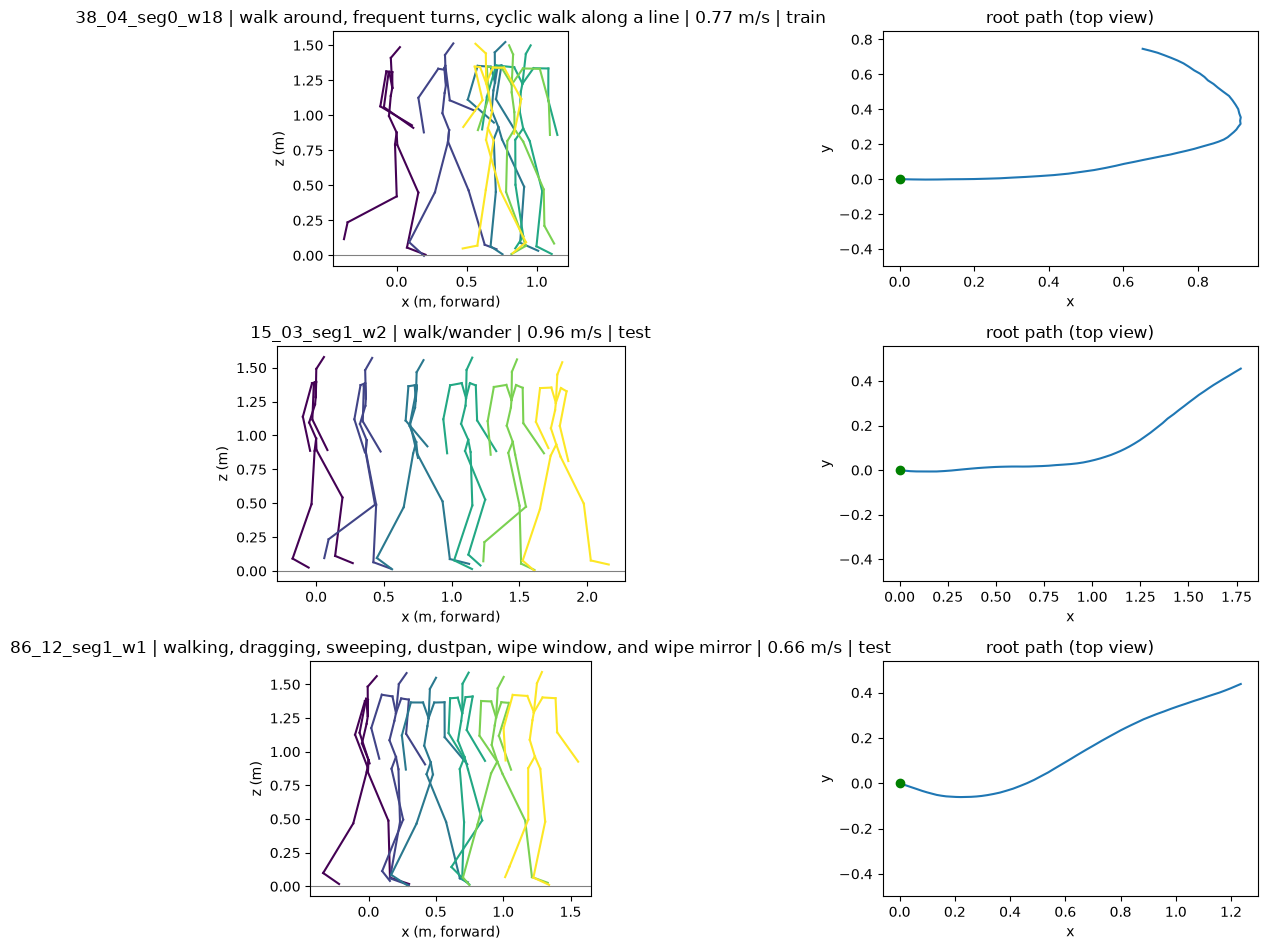

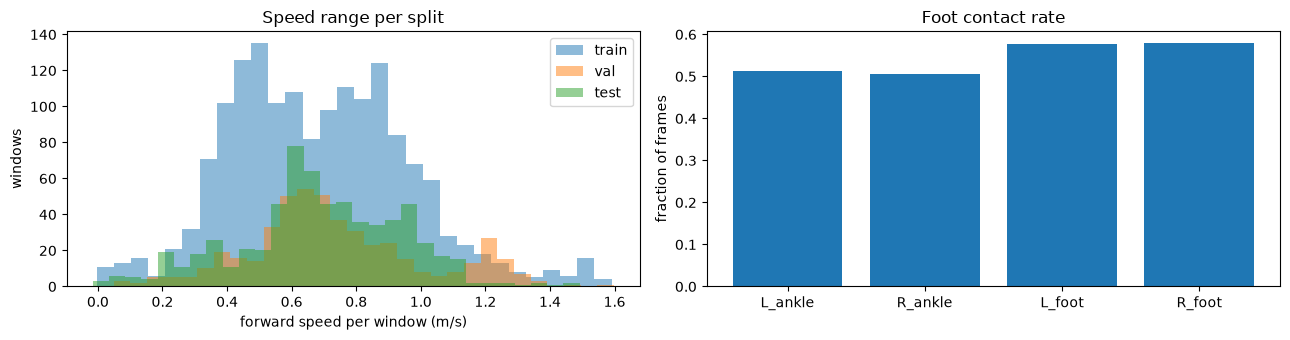

In [12]:
def draw(ax, P, color, alpha=1.0):
    for j, p in BONES:
        ax.plot([P[j, 0], P[p, 0]], [P[j, 2], P[p, 2]], color=color, alpha=alpha, lw=1.5)

rng_plot = np.random.default_rng(0)
picks = rng_plot.choice(len(JW), size=min(3, len(JW)), replace=False)
fig, axes = plt.subplots(len(picks), 2, figsize=(14, 3.2 * len(picks)), gridspec_kw={"width_ratios": [3, 1]}, squeeze=False)
for row, i in zip(axes, picks):
    W = JW[i]
    for k, t in enumerate(np.linspace(0, len(W) - 1, 6).astype(int)):
        draw(row[0], W[t], plt.cm.viridis(k / 5))
    row[0].axhline(0, color="grey", lw=.8); row[0].set_aspect("equal")
    m = meta.iloc[i]
    row[0].set_title(f"{m.window_id} | {m.description} | {m.fwd_speed_mps:.2f} m/s | {m.split}")
    row[0].set(xlabel="x (m, forward)", ylabel="z (m)")
    row[1].plot(W[:, 0, 0], W[:, 0, 1]); row[1].plot(0, 0, "go")
    row[1].set_ylim(min(-0.5, W[:, 0, 1].min() - .1), max(0.5, W[:, 0, 1].max() + .1))
    row[1].set(title="root path (top view)", xlabel="x", ylabel="y")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for split in ["train", "val", "test"]:
    ax[0].hist(meta.fwd_speed_mps[meta.split == split], bins=30, alpha=.5, label=split)
ax[0].set(xlabel="forward speed per window (m/s)", ylabel="windows", title="Speed range per split"); ax[0].legend()
c = X_full[..., CONTACT_COLS].mean((0, 1))
ax[1].bar(FOOT_NAMES, c); ax[1].set(ylabel="fraction of frames", title="Foot contact rate")
plt.tight_layout(); plt.show()

**What to expect on real data:** each foot should be in contact for roughly 55–65 % of frames when walking. Much lower means the contact thresholds (`CONTACT_VEL`, `CONTACT_HEIGHT`) are too strict; much higher means they are too loose.

## How to load the result later
```python
import numpy as np, pandas as pd, json
d    = np.load(r"...\walking\preprocessed\train.npz")
X    = d["X"]          # (N, 60, 134) normalised features -> model input
Xnr  = d["X_noroot"]   # (N, 60, 131) no-root ablation version
J3d  = d["joints"]     # (N, 60, 22, 3) joint positions in metres (for measuring speed, cadence, ...)
meta = pd.read_csv(r"...\walking\preprocessed\train_meta.csv")   # speed, subject, labels per window
norm = np.load(r"...\walking\preprocessed\normalization.npz")
cfg  = json.load(open(r"...\walking\preprocessed\config.json"))  # feature names, settings
# decoded output -> joints:  recover_joints(x * norm["std"] + norm["mean"])
```